Exercises : 

Conceptual: 

Exercise 1:
(a): 

We wish to prove:

$\frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^p (x_{ij} - x_{i'j})^2 = 2 \sum_{i \in C_k} \sum_{j=1}^p (x_{ij} - \bar{x}_{kj})^2$

where $\bar{x}_{kj} = \frac{1}{|C_k|} \sum_{i \in C_k} x_{ij}$ is the mean for feature $j$ in cluster $C_k$.

It is enough to prove the identity for a single feature $j$. The full result follows by summing over all $p$ features $j = 1, \dots, p$.

For a fixed feature $j$, expand the term $(x_{ij} - x_{i'j})^2$ by adding and subtracting $\bar{x}_{kj}$:

$(x_{ij} - x_{i'j})^2 = \Big( (x_{ij} - \bar{x}_{kj}) - (x_{i'j} - \bar{x}_{kj}) \Big)^2$

$(x_{ij} - x_{i'j})^2 = (x_{ij} - \bar{x}_{kj})^2 - 2(x_{ij} - \bar{x}_{kj})(x_{i'j} - \bar{x}_{kj}) + (x_{i'j} - \bar{x}_{kj})^2$

$\sum_{i, i' \in C_k} (x_{ij} - x_{i'j})^2 = \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})^2 - 2 \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})(x_{i'j} - \bar{x}_{kj}) + \sum_{i, i' \in C_k} (x_{i'j} - \bar{x}_{kj})^2$

Let's evaluate each of the three terms on the right-hand side:

1. **First Term:** Since $(x_{ij} - \bar{x}_{kj})^2$ does not depend on $i'$, summing over $i' \in C_k$ yields a factor of $|C_k|$:
   $$
   \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})^2 = |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2
   $$

2. **Third Term:** By symmetry with the first term:
   $$
   \sum_{i, i' \in C_k} (x_{i'j} - \bar{x}_{kj})^2 = |C_k| \sum_{i' \in C_k} (x_{i'j} - \bar{x}_{kj})^2 = |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2
   $$

3. **Middle Term:** We can split the double sum:
   $$
   \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})(x_{i'j} - \bar{x}_{kj}) = \left( \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj}) \right) \left( \sum_{i' \in C_k} (x_{i'j} - \bar{x}_{kj}) \right)
   $$
   By definition of the sample mean $\bar{x}_{kj}$:
   $$
   \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj}) = \sum_{i \in C_k} x_{ij} - |C_k| \bar{x}_{kj} = |C_k|\bar{x}_{kj} - |C_k|\bar{x}_{kj} = 0
   $$
   Therefore, the middle term equals $0$.

Combining all three terms:

$\sum_{i, i' \in C_k} (x_{ij} - x_{i'j})^2 = |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2 + 0 + |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2 = 2 |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2$

Dividing both sides by $|C_k|$:

$\frac{1}{|C_k|} \sum_{i, i' \in C_k} (x_{ij} - x_{i'j})^2 = 2 \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2$

Summing over all features $j = 1, \dots, p$ completes the proof:

$\frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^p (x_{ij} - x_{i'j})^2 = 2 \sum_{i \in C_k} \sum_{j=1}^p (x_{ij} - \bar{x}_{kj})^2 \quad \blacksquare$



(b)

Using (12.18), the objective function in (12.17) can be rewritten as:

$\sum_{k=1}^K \frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^p (x_{ij} - x_{i'j})^2 = 2 \sum_{k=1}^K \sum_{i \in C_k} \sum_{j=1}^p (x_{ij} - \bar{x}_{kj})^2$

Minimizing the original objective function is therefore equivalent to minimizing:

$f(C_1, \dots, C_K, m_1, \dots, m_K) = \sum_{k=1}^K \sum_{i \in C_k} \| x_i - m_k \|^2$

where $m_k = (\bar{x}_{k1}, \dots, \bar{x}_{kp})^T$ is the centroid of cluster $k$.


Exercise 2:


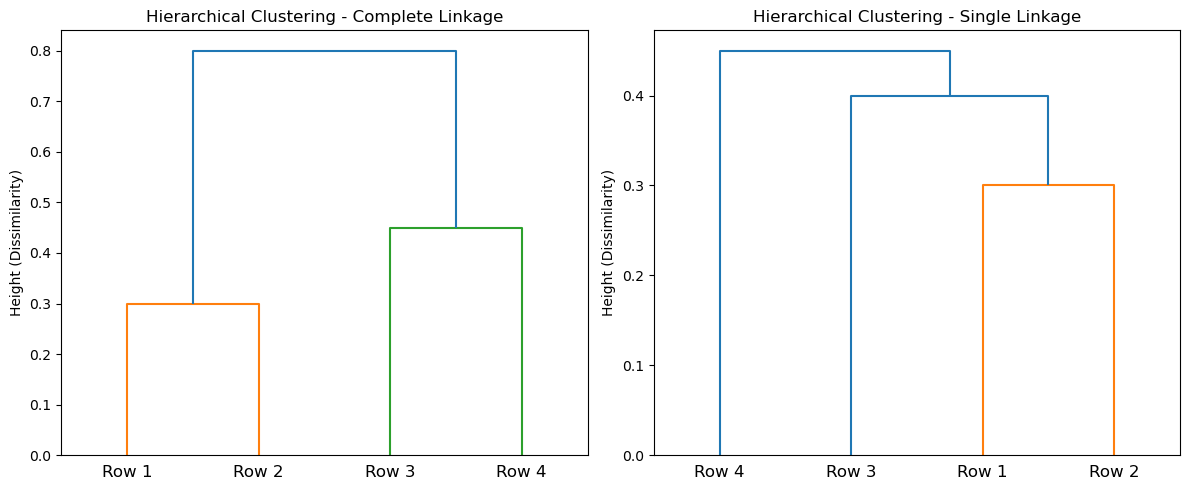

In [5]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
import numpy as np

dist_matrix = np.array([
    [0.0,  0.3,  0.4,  0.7],
    [0.3,  0.0,  0.5,  0.8],
    [0.4,  0.5,  0.0,  0.45],
    [0.7,  0.8,  0.45, 0.0]
])

condensed_dist = squareform(dist_matrix)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# (a)
linkage_complete = linkage(condensed_dist, method='complete')
dendrogram(linkage_complete, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[0])
axes[0].set_title('Hierarchical Clustering - Complete Linkage')
axes[0].set_ylabel('Height (Dissimilarity)')

# (b)
linkage_single = linkage(condensed_dist, method='single')
dendrogram(linkage_single, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[1])
axes[1].set_title('Hierarchical Clustering - Single Linkage')
axes[1].set_ylabel('Height (Dissimilarity)')

plt.tight_layout()
plt.show()

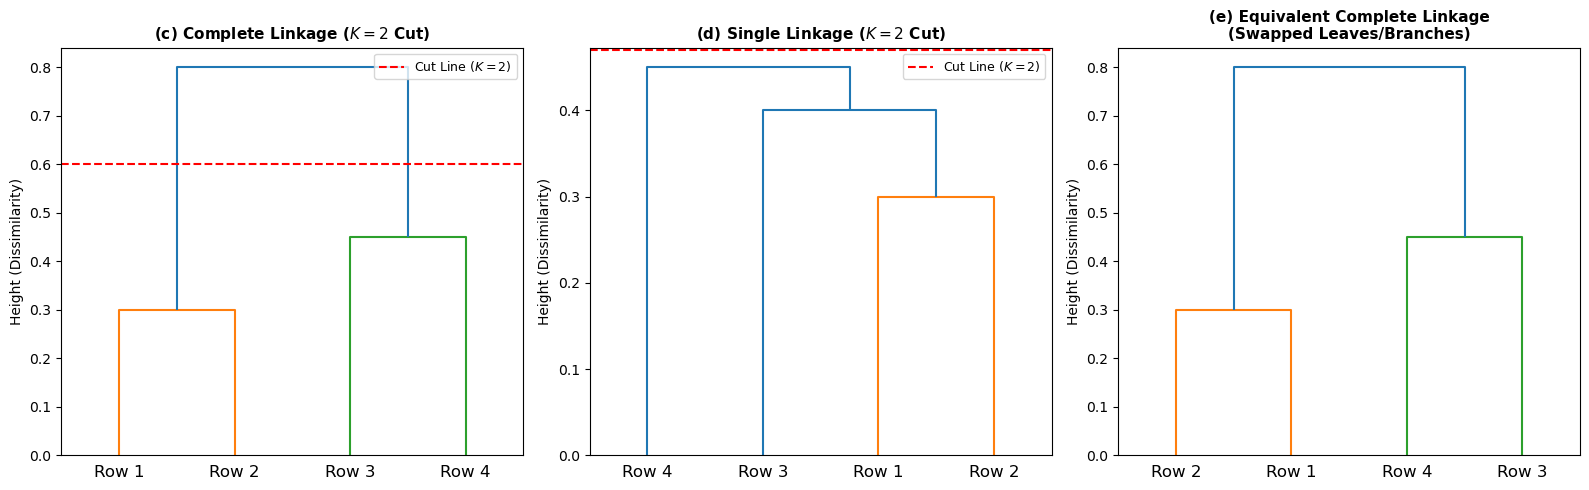

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (c) Complete Linkage Cut for K=2 
linkage_complete = linkage(condensed_dist, method='complete')
dendrogram(linkage_complete, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[0])
axes[0].set_title('(c) Complete Linkage ($K=2$ Cut)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Height (Dissimilarity)')
# Add a horizontal cut line that splits the tree into 2 clusters: {1,2} and {3,4}
axes[0].axhline(y=0.6, color='red', linestyle='--', linewidth=1.5, label='Cut Line ($K=2$)')
axes[0].legend(loc='upper right', fontsize=9)

#(d) Single Linkage Cut for K=2 
linkage_single = linkage(condensed_dist, method='single')
dendrogram(linkage_single, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[1])
axes[1].set_title('(d) Single Linkage ($K=2$ Cut)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Height (Dissimilarity)')
# Add a horizontal cut line that splits the tree into 2 clusters: {1,2,3} and {4}
axes[1].axhline(y=0.47, color='red', linestyle='--', linewidth=1.5, label='Cut Line ($K=2$)')
axes[1].legend(loc='upper right', fontsize=9)

#(e) Equivalent Complete Linkage with Swapped Leaves 
dendrogram(
    linkage_complete, 
    labels=['Row 2', 'Row 1', 'Row 4', 'Row 3'],  
    ax=axes[2]
)
axes[2].set_title('(e) Equivalent Complete Linkage\n(Swapped Leaves/Branches)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Height (Dissimilarity)')

plt.tight_layout()
plt.show()

Exercise 3:

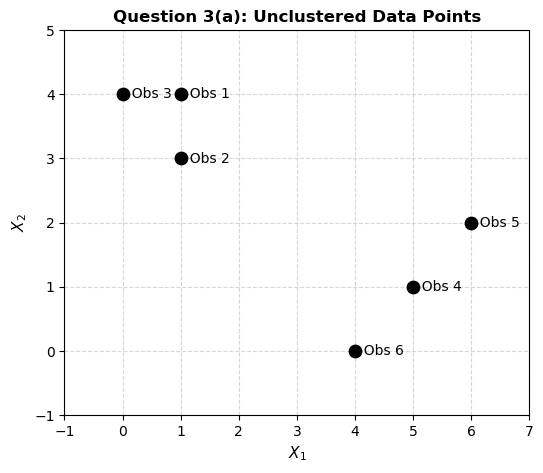

In [16]:
#(a)
X = np.array([
    [1, 4],  
    [1, 3],  
    [0, 4],  
    [5, 1],  
    [6, 2],  
    [4, 0]   
])

obs_labels = [1, 2, 3, 4, 5, 6]


plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], color='black', s=80, zorder=3)


for i, txt in enumerate(obs_labels):
    plt.annotate(f'  Obs {txt}', (X[i, 0], X[i, 1]), fontsize=10, verticalalignment='center')

plt.title('Question 3(a): Unclustered Data Points', fontsize=12, fontweight='bold')
plt.xlabel('$X_1$', fontsize=11)
plt.ylabel('$X_2$', fontsize=11)
plt.xlim(-1, 7)
plt.ylim(-1, 5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

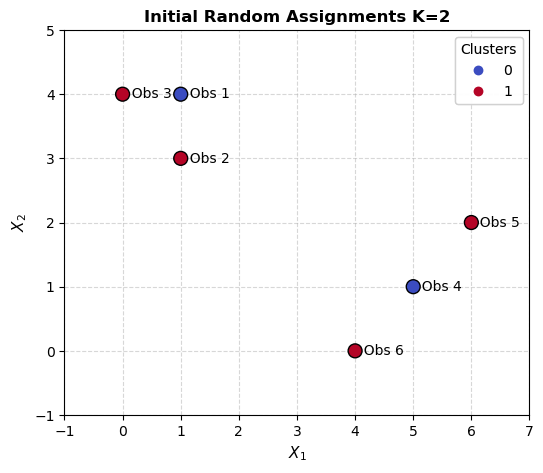

In [17]:
#(b)
np.random.seed(0)
initial_labels = np.random.choice([0, 1], size=len(X))

plt.figure(figsize=(6, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=initial_labels, cmap='coolwarm', s=100, edgecolor='k', zorder=3)
legend1 = plt.legend(*scatter.legend_elements(), title="Clusters")
plt.gca().add_artist(legend1)

for i, txt in enumerate(range(1, 7)):
    plt.annotate(f'  Obs {txt}', (X[i, 0], X[i, 1]), fontsize=10, verticalalignment='center')

plt.title('Initial Random Assignments K=2', fontsize=12, fontweight='bold')
plt.xlabel('$X_1$', fontsize=11)
plt.ylabel('$X_2$', fontsize=11)
plt.xlim(-1, 7)
plt.ylim(-1, 5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [20]:
#(c)




centroid_0 = np.mean(X[initial_labels == 0], axis=0)
centroid_1 = np.mean(X[initial_labels == 1], axis=0)

print(f"Cluster 0 members: {np.where(initial_labels == 0)[0] + 1}")
print(f"Cluster 0 Centroid: {centroid_0}")
print("-" * 20)
print(f"Cluster 1 members: {np.where(initial_labels == 1)[0] + 1}")
print(f"Cluster 1 Centroid: {centroid_1}")



Cluster 0 members: [1 4]
Cluster 0 Centroid: [3.  2.5]
--------------------
Cluster 1 members: [2 3 5 6]
Cluster 1 Centroid: [2.75 2.25]


In [22]:
#(d)
def assign_clusters(X, c0, c1):
    new_labels = []
    for x in X:
        d0 = np.linalg.norm(x - c0)
        d1 = np.linalg.norm(x - c1)
        new_labels.append(0 if d0 < d1 else 1)
    return np.array(new_labels)

updated_labels = assign_clusters(X, centroid_0, centroid_1)

print("Updated Cluster Assignments after Distance Comparison:")
for i, label in enumerate(updated_labels, start=1):
    print(f"Observation {i} -> Assigned to Cluster {label}")



Updated Cluster Assignments after Distance Comparison:
Observation 1 -> Assigned to Cluster 1
Observation 2 -> Assigned to Cluster 1
Observation 3 -> Assigned to Cluster 1
Observation 4 -> Assigned to Cluster 0
Observation 5 -> Assigned to Cluster 0
Observation 6 -> Assigned to Cluster 1


In [23]:
#(e)

np.random.seed(42)
labels = np.random.choice([0, 1], size=len(X))
iteration = 0
converged = False

print("Starting K-means Iterative Optimization:\n" + "-"*40)

while not converged:
    iteration += 1
    c0 = np.mean(X[labels == 0], axis=0)
    c1 = np.mean(X[labels == 1], axis=0)
    

    new_labels = []
    for x in X:
        d0 = np.linalg.norm(x - c0)
        d1 = np.linalg.norm(x - c1)
        new_labels.append(0 if d0 < d1 else 1)
    new_labels = np.array(new_labels)
    
    print(f"Iteration {iteration}:")
    print(f"  Cluster 0 Centroid: {c0}, Members: {np.where(labels == 0)[0] + 1}")
    print(f"  Cluster 1 Centroid: {c1}, Members: {np.where(labels == 1)[0] + 1}")
    print(f"  New Labels: {new_labels}\n")
    
    if np.array_equal(labels, new_labels):
        converged = True
        print(f"Algorithm converged after {iteration} iterations!")
    else:
        labels = new_labels

Starting K-means Iterative Optimization:
----------------------------------------
Iteration 1:
  Cluster 0 Centroid: [3.   2.75], Members: [1 3 4 5]
  Cluster 1 Centroid: [2.5 1.5], Members: [2 6]
  New Labels: [0 0 0 1 0 1]

Iteration 2:
  Cluster 0 Centroid: [2.   3.25], Members: [1 2 3 5]
  Cluster 1 Centroid: [4.5 0.5], Members: [4 6]
  New Labels: [0 0 0 1 1 1]

Iteration 3:
  Cluster 0 Centroid: [0.66666667 3.66666667], Members: [1 2 3]
  Cluster 1 Centroid: [5. 1.], Members: [4 5 6]
  New Labels: [0 0 0 1 1 1]

Algorithm converged after 3 iterations!


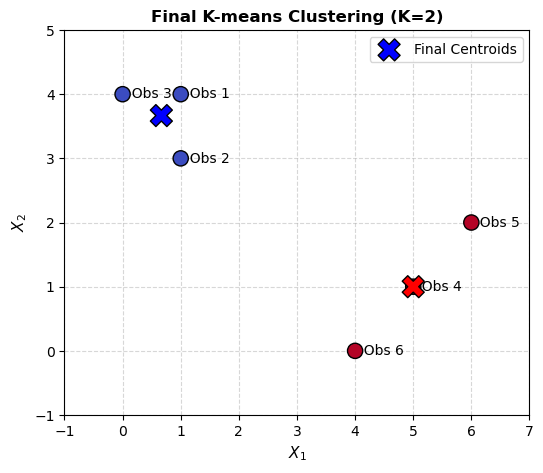

In [24]:
#(f)


final_labels = np.array([0, 0, 0, 1, 1, 1]) 
final_c0 = np.mean(X[final_labels == 0], axis=0)
final_c1 = np.mean(X[final_labels == 1], axis=0)


plt.figure(figsize=(6, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=final_labels, cmap='coolwarm', s=120, edgecolor='k', zorder=3)
plt.scatter([final_c0[0], final_c1[0]], [final_c0[1], final_c1[1]], 
            color=['blue', 'red'], marker='X', s=250, edgecolor='k', label='Final Centroids', zorder=4)

for i, txt in enumerate(range(1, 7)):
    plt.annotate(f'  Obs {txt}', (X[i, 0], X[i, 1]), fontsize=10, verticalalignment='center')

plt.title('Final K-means Clustering (K=2)', fontsize=12, fontweight='bold')
plt.xlabel('$X_1$', fontsize=11)
plt.ylabel('$X_2$', fontsize=11)
plt.xlim(-1, 7)
plt.ylim(-1, 5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

Exercise 4

(a)

*Answer:*
The fusion for *complete linkage* will occur *higher* on the tree than for single linkage.

* Reasoning:
*Single Linkage* defines the dissimilarity between two clusters $A$ and $B$ as the minimum pairwise distance between points in the two clusters: $d_{\text{single}}(A, B) = \min_{i \in A, j \in B} d(i, j)$


*Complete Linkage* defines the dissimilarity as the *maximum* pairwise distance between points in the two clusters:$d_{\text{complete}}(A, B) = \max_{i \in A, j \in B} d(i, j)$

so, the fusion height for complete linkage will always be at or above the fusion height for single linkage:



(b)

*Answer:**
They will fuse at the *exact same height*.

* Reasoning:
When fusing two clusters that each consist of a **single observation** (i.e., singleton clusters like $\{5\}$ and $\{6\}$), there is only one pair of points to compare ($i=5$ and $j=6$). 

Therefore, the minimum distance and the maximum distance between them are identical:
$ \min(d(5,6)) = \max(d(5,6)) = d(5,6) $

Because both linkage methods collapse to the exact same pairwise distance for singletons, the fusion height is identical on both dendrograms.

Exercise 5: 


* Left Plot: Raw Variables (Number of Items Purchased)


The clustering will be entirely driven by the number of socks purchased, while computer purchases will have virtually no effect. 
so, the number of socks purchased ranges roughly from 5 to 11, whereas the number of computers purchased ranges only from 0 to 1. Because Euclidean distance is sensitive to the scale of the data, the much larger numerical variance in sock purchases completely dominates the distance calculations, rendering computer purchases statistically negligible.



* Center Plot: Variables Scaled by Standard Deviation (Z-score Scaling)


The clustering will take **both products into balanced consideration**, grouping shoppers based on a combined measure of their relative purchasing behaviors for both socks and computers.
Each variable is scaled by its standard deviation, meaning both socks and computers are given comparable variance and equal weight in the Euclidean distance calculation. Neither variable dominates, so the clusters reflect true combined shopping habits across both items

* Right Plot: Monetary Value (Dollars Spent)


The clustering will be entirely driven by computer purchases (dollars spent on computers), while sock purchases will become completely invisible.
Since a computer costs vastly more than a pair of socks, the scale of dollars spent on computers stretches into thousands (0 to over 1500), whereas money spent on socks remains a tiny fraction (< 100). Consequently, the massive variance in monetary value for computers will entirely dominate the inter-observation Euclidean distances, completely overriding the sock purchase history

Exercise 6:



1. **Rewriting the Optimization Problem:**
   In PCA approximation, equation (12.6) seeks to minimize the reconstruction error of the data matrix $\mathbf{X}$ using rank-$M$ matrix factorization:
   
   $$
   \min_{\mathbf{A} \in \mathbb{R}^{n \times M}, \mathbf{B} \in \mathbb{R}^{p \times M}} \left\{ \sum_{j=1}^p \sum_{i=1}^n \left( x_{ij} - \sum_{m=1}^M a_{im} b_{jm} \right)^2 \right\}
   $$

   Here:
   * $a_{im} = z_{im}$ are the elements of the score vectors (known predictors).
   * $b_{jm} = \phi_{jm}$ are the elements of the loading vectors (unknown coefficients to estimate).
   * $x_{ij}$ represents the feature values of the data matrix.

2. **Decoupling Across Features ($j$):**
   Notice that the outer sum runs over each feature $j$ from $1$ to $p$. The choice of loading coefficients for a specific feature $j$ (i.e., $b_{j1}, b_{j2}, \dots, b_{jM}$) only affects the $j$-th term inside the summation:
   
   $$
   \sum_{i=1}^n \left( x_{ij} - \sum_{m=1}^M z_{im} \phi_{jm} \right)^2
   $$

   Because the minimization problem is a sum over independent features $j = 1, \dots, p$, **minimizing the total objective function is mathematically equivalent to minimizing each feature's squared error separately.**

3. **Formulation as Ordinary Least Squares (OLS):**
   For any given feature $j$, the expression:
   
   $$
   \sum_{i=1}^n \left( x_{ij} - \sum_{m=1}^M z_{im} \phi_{jm} \right)^2
   $$

   is precisely the sum of squared residuals for a linear regression model where:
   * **The response variable** is the $j$-th feature column of the data matrix, $y_j = (x_{1j}, x_{2j}, \dots, x_{nj})^T$.
   * **The predictors** are the $M$ principal component score vectors, $z_{im}$ for $m = 1, \dots, M$.
   * **The regression coefficients** to be estimated are the loading vector components, $\phi_{j1}, \phi_{j2}, \dots, \phi_{jM}$ (with no intercept, as PCA assumes centered features).


if the score vectors $z_{im}$ are known, each of the $p$ feature loading vectors can be obtained independently by running **$p$ separate multiple linear regressions** (one for each feature $x_{\cdot j}$ against the $M$ score vectors $z_{\cdot m}$), where the resulting regression coefficients correspond directly to the principal component loadings $\phi_{jm}$. 

Exercises:

Applied:

Exercise 7:

In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from ISLP import load_data

from sklearn.cluster import (KMeans,AgglomerativeClustering)
from scipy.cluster.hierarchy import (dendrogram,cut_tree)
from ISLP.cluster import compute_linkage

In [32]:
USArrests = get_rdataset('USArrests').data
USArrests.head(5)

,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [138]:
from sklearn.metrics import pairwise_distances

X = USArrests.values  
n, p = X.shape

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.T).T

sq_euclid_dist = pairwise_distances(X_scaled, metric='sqeuclidean')


In [139]:
corr_matrix = np.corrcoef(X_scaled)

In [140]:
one_minus_r = 1.0 - corr_matrix

In [141]:

expected_proportional = 2 * p * one_minus_r

max_diff = np.max(np.abs(sq_euclid_dist - expected_proportional))
print(f"Maximum absolute difference between squared Euclidean distance and 2p(1 - r_ij): {max_diff:.2e}")

Maximum absolute difference between squared Euclidean distance and 2p(1 - r_ij): 4.11e-15


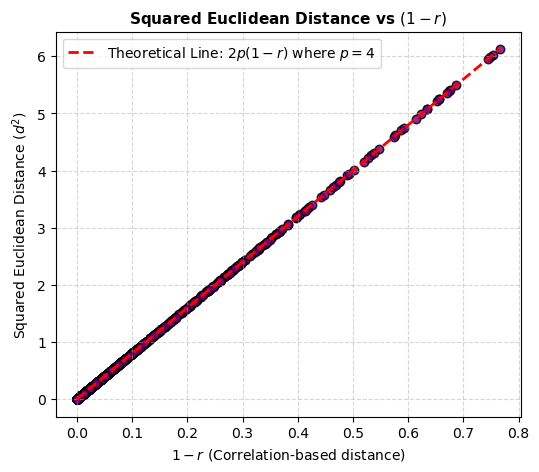

In [142]:

plt.figure(figsize=(6, 5))
plt.scatter(one_minus_r.flatten(), sq_euclid_dist.flatten(), color='purple', alpha=0.6, edgecolor='k')
plt.title('Squared Euclidean Distance vs $(1 - r)$', fontsize=11, fontweight='bold')
plt.xlabel('$1 - r$ (Correlation-based distance)', fontsize=10)
plt.ylabel('Squared Euclidean Distance ($d^2$)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

x_vals = np.linspace(0, np.max(one_minus_r), 100)
plt.plot(x_vals, 2 * p * x_vals, color='red', 
         linestyle='--', 
         linewidth=2, 
         label=f'Theoretical Line: $2p(1-r)$ where $p={p}$')
plt.legend(loc='upper left')
plt.show()

Exercise 8:

In [46]:
USArrests.var()

Murder        18.970465
Assault     6945.165714
UrbanPop     209.518776
Rape          87.729159
dtype: float64

In [47]:
scaler = StandardScaler(with_std=True,
with_mean=True)
USArrests_scaled = scaler.fit_transform(USArrests)

In [48]:
pcaUS = PCA()

In [49]:
pcaUS.fit(USArrests_scaled)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [50]:
scores = pcaUS.transform(USArrests_scaled)

In [58]:
#(a)

pcaUS.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

In [56]:
%%capture
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ticks = np.arange(pcaUS.n_components_)+1
ax = axes[0]
ax.plot(ticks,
        pcaUS.explained_variance_ratio_,
        marker='o')
ax.set_xlabel('Principal Component');
ax.set_ylabel('Proportion of Variance Explained')
ax.set_ylim([0,1])
ax.set_xticks(ticks)


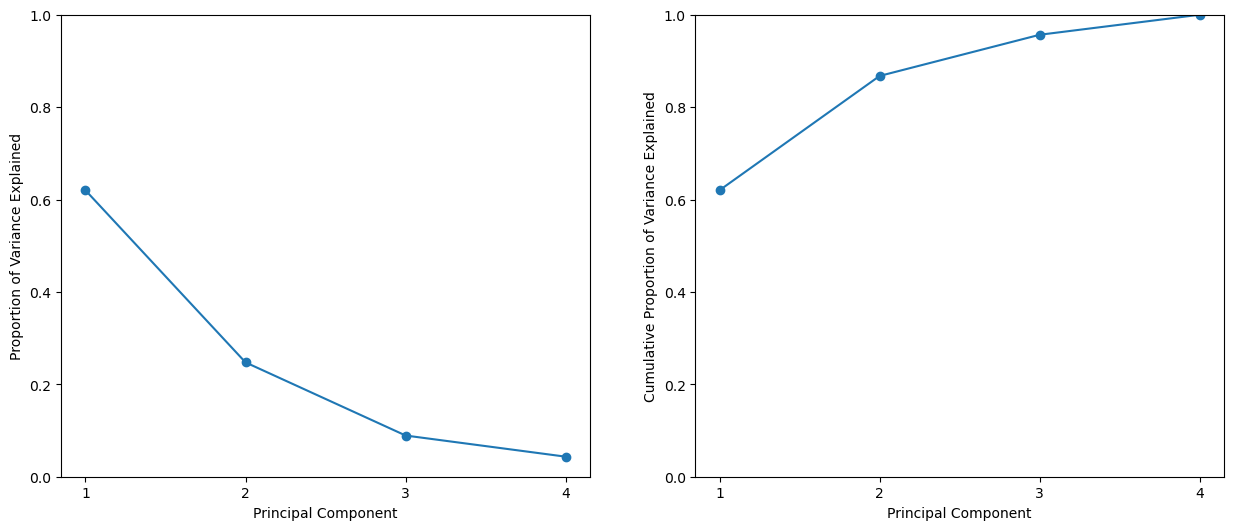

In [57]:
ax = axes[1]
ax.plot(ticks,
        pcaUS.explained_variance_ratio_.cumsum(),
        marker='o')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Cumulative Proportion of Variance Explained')
ax.set_ylim([0, 1])
ax.set_xticks(ticks)
fig


In [59]:
#(b)
pcaUS.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

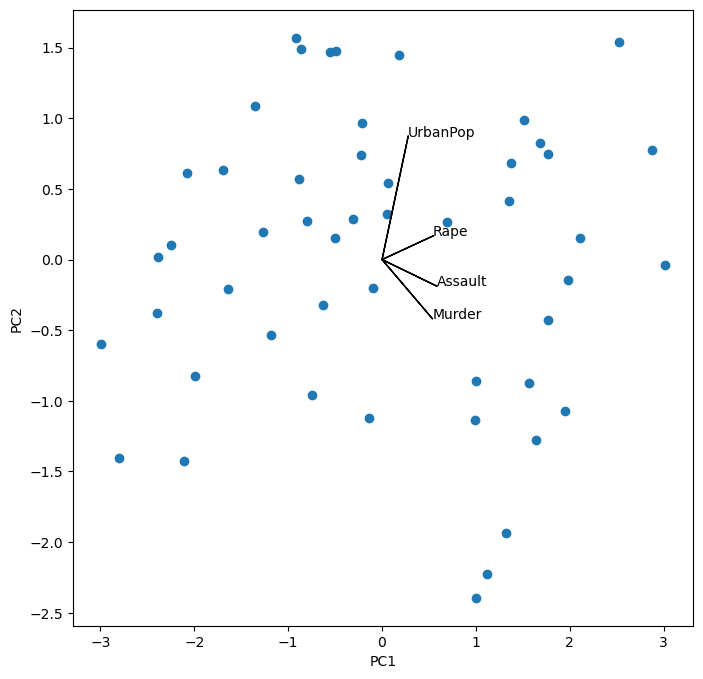

In [60]:
i, j = 0, 1 # which components
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(scores[:,0], scores[:,1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape[1]):
    ax.arrow(0, 0, pcaUS.components_[i,k], pcaUS.components_[j,k])
    ax.text(pcaUS.components_[i,k],
    pcaUS.components_[j,k],
    USArrests.columns[k])

    

In [62]:
X_scaled = USArrests_scaled
n_obs = X_scaled.shape[0]
total_ss = np.sum(X_scaled ** 2)

pve_manual = []
for m in range(pcaUS.components_.shape[0]):
    phi_m = pcaUS.components_[m]
    scores_m = np.dot(X_scaled, phi_m)
    ss_m = np.sum(scores_m ** 2)
    pve_manual.append(ss_m / total_ss)

print("PVE from explained_variance_ratio_ (a):", pcaUS.explained_variance_ratio_)
print("PVE calculated manually via Equation 12.10 (b):", np.array(pve_manual))

PVE from explained_variance_ratio_ (a): [0.62006039 0.24744129 0.0891408  0.04335752]
PVE calculated manually via Equation 12.10 (b): [0.62006039 0.24744129 0.0891408  0.04335752]


Exercise 9:

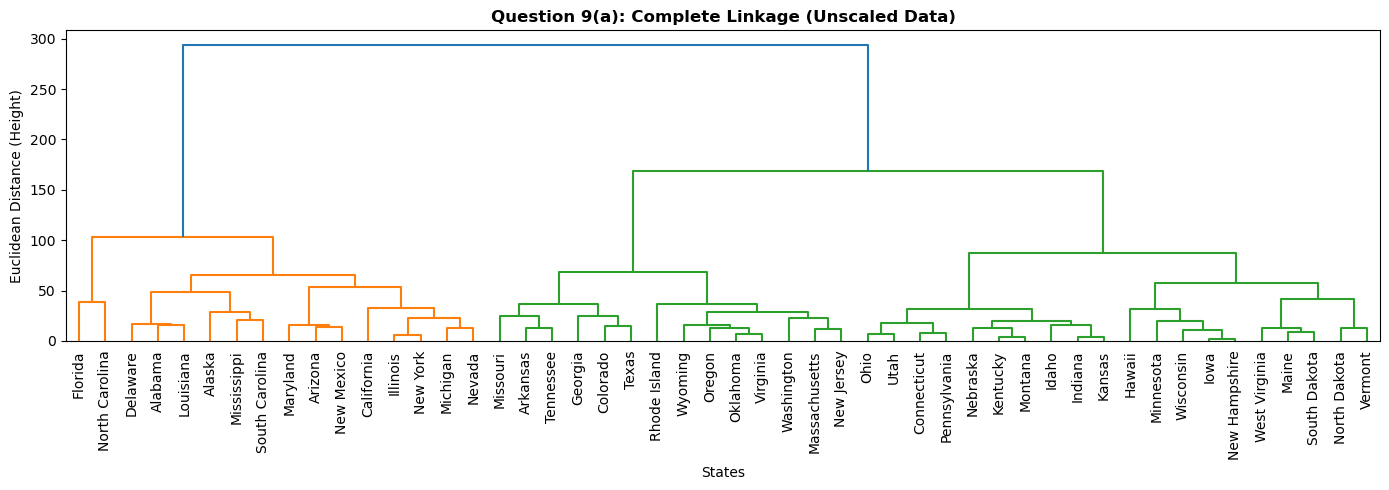

In [78]:
#(a)
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_unscaled = linkage(USArrests, method='complete', metric='euclidean')

# 3. Plot Dendrogram
plt.figure(figsize=(14, 5))
dendrogram(linkage_unscaled, labels=USArrests.index.values, leaf_font_size=10)
plt.title('Question 9(a): Complete Linkage (Unscaled Data)', fontsize=12, fontweight='bold')
plt.xlabel('States')
plt.ylabel('Euclidean Distance (Height)')
plt.tight_layout()
plt.show()

In [80]:
#(b)

from scipy.cluster.hierarchy import fcluster

labels_unscaled = fcluster(linkage_unscaled, t=3, criterion='maxclust')
df_unscaled = pd.DataFrame({'State': USArrests.index, 'Cluster': labels_unscaled})


for c_id in sorted(df_unscaled['Cluster'].unique()):
    states = df_unscaled[df_unscaled['Cluster'] == c_id]['State'].values
    print(f"Cluster {c_id} ({len(states)} states): {', '.join(states)}\n")

Cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina

Cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming

Cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin



In [81]:
#(c)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(USArrests)

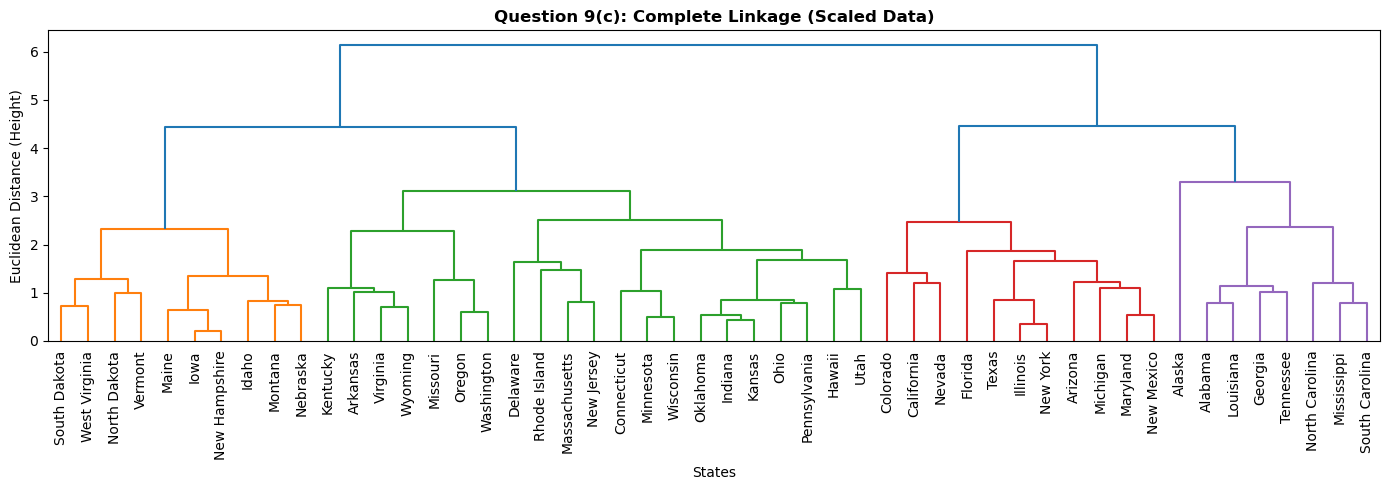

In [84]:

linkage_scaled = linkage(X_scaled, method='complete', metric='euclidean')

plt.figure(figsize=(14, 5))
dendrogram(linkage_scaled, labels=USArrests.index.values, leaf_font_size=10)
plt.title('Question 9(c): Complete Linkage (Scaled Data)', fontsize=12, fontweight='bold')
plt.xlabel('States')
plt.ylabel('Euclidean Distance (Height)')
plt.tight_layout()
plt.show()


In [86]:

labels_scaled = fcluster(linkage_scaled, t=3, criterion='maxclust')
df_scaled = pd.DataFrame({'State': USArrests.index, 'Cluster': labels_scaled})

for c_id in sorted(df_scaled['Cluster'].unique()):
    states = df_scaled[df_scaled['Cluster'] == c_id]['State'].values
    print(f"Cluster {c_id} ({len(states)} states): {', '.join(states)}\n")

Cluster 1 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming

Cluster 2 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas

Cluster 3 (8 states): Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee



(d): Should the Variables Be Scaled?


**Yes, the variables should be scaled before performing hierarchical clustering.**


**Variance Disparity:** In the unscaled USArrests dataset, the variance of Assault (6945) is vastly larger than that of Murder (18.97), Rape (87.7), and UrbanPop(209.5). 

**Dominance of Units:** Because Euclidean distance depends on measurement units, clustering unscaled data effectively causes Assault alone to dictate the distances between states, treating the other crime statistics as negligible.

**Equal Weighting:** Scaling standardizes each feature to have standard deviation 1, ensuring that each variable (Murder, Assault, UrbanPop, Rape) contributes equally to the distance matrix and resulting cluster assignments.

Exersice 10:


In [99]:
#(a)

np.random.seed(42)
class1 = np.random.normal(loc=0.0, scale=1.0, size=(20, 50))
class2 = np.random.normal(loc=3.5, scale=1.0, size=(20, 50))
class3 = np.random.normal(loc=-3.5, scale=1.0, size=(20, 50))

X = np.vstack([class1, class2, class3])
true_labels = np.array([0]*20 + [1]*20 + [2]*20)

print("Data matrix shape:", X.shape)
print("True labels shape:", true_labels.shape)

Data matrix shape: (60, 50)
True labels shape: (60,)


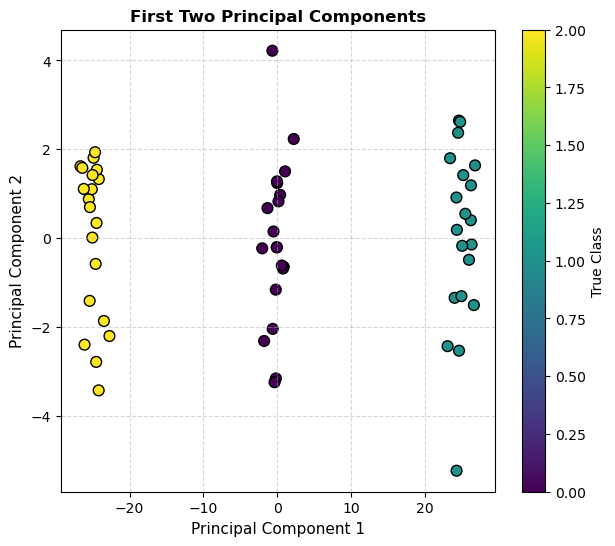

In [101]:
#(b)

pca = PCA(n_components=2)
scores = pca.fit_transform(X)

plt.figure(figsize=(7, 6))
scatter = plt.scatter(scores[:, 0], scores[:, 1], c=true_labels, cmap='viridis', s=60, edgecolor='k')
plt.title('First Two Principal Components', fontsize=12, fontweight='bold')
plt.xlabel('Principal Component 1', fontsize=11)
plt.ylabel('Principal Component 2', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.colorbar(scatter, label='True Class')
plt.show()

In [102]:
#(c)


kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X)
cluster_labels = kmeans.labels_

crosstab = pd.crosstab(true_labels, cluster_labels, rownames=['True Class'], colnames=['K-means Cluster'])
print("Cross-Tabulation of True Classes vs K-Means Clusters:")
display(crosstab)

Cross-Tabulation of True Classes vs K-Means Clusters:


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-means Cluster,0,1,2
True Class,,,
0,0,0,20
1,20,0,0
2,0,20,0


In [103]:
#(d)


kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X)
cluster_labels = kmeans.labels_

crosstab = pd.crosstab(true_labels, cluster_labels, rownames=['True Class'], colnames=['K-means Cluster'])
print("Cross-Tabulation of True Classes vs K-Means Clusters:")
display(crosstab)

Cross-Tabulation of True Classes vs K-Means Clusters:


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-means Cluster,0,1
True Class,,
0,0,20
1,20,0
2,0,20



When we perform K-means clustering with K = 2 on our simulated dataset containing 3 distinct classes, the algorithm merges two of the classes into a single cluster while keeping the third class separate. 

Specifically, looking at the cross-tabulation:
* **One cluster** entirely captures one of the original classes (all 20 observations of True Class 1 are grouped together into Cluster 0).
* **The second cluster** absorbs the remaining two classes (all 20 observations of True Class 0 and all 20 observations of True Class 2 are combined into Cluster 1).


In [105]:
#(e)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X)
cluster_labels = kmeans.labels_

crosstab = pd.crosstab(true_labels, cluster_labels, rownames=['True Class'], colnames=['K-means Cluster'])
print("Cross-Tabulation of True Classes vs K-Means Clusters:")
display(crosstab)

Cross-Tabulation of True Classes vs K-Means Clusters:


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-means Cluster,0,1,2,3
True Class,,,,
0,0,0,20,0
1,10,0,0,10
2,0,20,0,0


When we perform $K$-means clustering with $K = 4$ on our dataset (which actually contains 3 distinct true classes), the algorithm splits one of the true classes into two separate clusters while leaving the other two true classes intact.

Specifically, looking at the cross-tabulation:
* **True Class 0** is completely captured by a single cluster (all 20 observations are in Cluster 2).
* **True Class 2** is also completely captured by a single cluster (all 20 observations are in Cluster 1).
* **True Class 1**, however, is **split evenly in half** by the algorithm, with 10 observations assigned to Cluster 0 and the other 10 observations assigned to Cluster 3.



In [110]:
#(f)

pca = PCA(n_components=2)
scores = pca.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(scores)
cluster_labels = kmeans.labels_

crosstab = pd.crosstab(true_labels, cluster_labels, rownames=['True Class'], colnames=['K-means Cluster'])
print("Cross-Tabulation of True Classes vs K-Means Clusters (on PC scores):")
display(crosstab)

Cross-Tabulation of True Classes vs K-Means Clusters (on PC scores):


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-means Cluster,0,1,2
True Class,,,
0,0,0,20
1,20,0,0
2,0,20,0



When we perform $K$-means clustering with $K = 3$ directly on the first two principal component score vectors (rather than the original 50-dimensional raw data), we obtain a **perfect 1-to-1 match** with the true class labels. 

because:
The first two principal components successfully capture and project the dominant variance and class separation present across the 50 variables into a 2-dimensional subspace. Because the classes are well-separated in this reduced space, $K$-means can partition them just as effectively on the PC scores as it did on the full high-dimensional dataset.

In [111]:
#(g)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [112]:

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)
cluster_labels = kmeans.labels_

crosstab = pd.crosstab(true_labels, cluster_labels, rownames=['True Class'], colnames=['K-means Cluster'])
print("Cross-Tabulation of True Classes vs K-Means Clusters:")
display(crosstab)

Cross-Tabulation of True Classes vs K-Means Clusters:


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-means Cluster,0,1,2
True Class,,,
0,0,0,20
1,20,0,0
2,0,20,0



When we standardize each variable to have a standard deviation of one using StandardScaler and then perform $K$-means clustering with $K = 3$, the resulting cross-tabulation shows a **perfect 1-to-1 correspondence** with the true class labels. 

These results are identical to our initial $K$-means clustering on the raw data (and part (f)).

Since our simulated dataset was generated with uniform standard deviation across all 50 variables (and equal spread across classes), applying StandardScaler scales all features by a similar factor without distorting the relative distances or spatial separation between the three groups. Consequently, $K$-means successfully partitions the observations into their exact original classes.

Exercise 11:

In [118]:

Boston = load_data("Boston")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(Boston)

np.random.seed(42)
mask = np.random.rand(*X_scaled.shape) < 0.20  

X_incomplete = X_scaled.copy()
X_incomplete[mask] = np.nan 


In [119]:
X_tilde = X_incomplete.copy()
ismiss = np.isnan(X_tilde)

In [120]:
col_means = np.nanmean(X_tilde, axis=0)
for j in range(X_tilde.shape[1]):
    X_tilde[ismiss[:, j], j] = col_means[j]

print("Step 1 Complete: Missing values initialized to column means.")
print("Shape of X_tilde:", X_tilde.shape)

Step 1 Complete: Missing values initialized to column means.
Shape of X_tilde: (506, 13)


In [122]:
M = 2

U, D, Vt = np.linalg.svd(X_tilde, full_matrices=False)


U_m = U[:, :M]
D_m = D[:M]
Vt_m = Vt[:M, :]


X_app = (U_m * D_m[None, :]) @ Vt_m

print(f"Computed rank-{M} matrix approximation via SVD.")

Computed rank-2 matrix approximation via SVD.


In [123]:
X_tilde[ismiss] = X_app[ismiss]

In [124]:
observed_mask = ~ismiss
objective_value = np.sum((X_incomplete[observed_mask] - X_app[observed_mask])**2)

In [125]:
def iterative_matrix_completion(X_inc, M=2, max_iter=50, tol=1e-7):
    X_tilde = X_inc.copy()
    ismiss = np.isnan(X_tilde)
    observed_mask = ~ismiss
    
    # Step 1: Initialize missing values with column means
    col_means = np.nanmean(X_tilde, axis=0)
    for j in range(X_tilde.shape[1]):
        X_tilde[ismiss[:, j], j] = col_means[j]
        
    obj_old = np.inf
    
    for iteration in range(1, max_iter + 1):
        # Step 2a: Low-rank SVD approximation
        U, D, Vt = np.linalg.svd(X_tilde, full_matrices=False)
        X_app = (U[:, :M] * D[:M]) @ Vt[:M, :]
        
        # Step 2b: Update missing elements
        X_tilde[ismiss] = X_app[ismiss]
        
        # Step 2c: Compute objective
        obj_new = np.sum((X_inc[observed_mask] - X_app[observed_mask])**2)
        
        # Check convergence (stop if objective stops decreasing significantly)
        if abs(obj_old - obj_new) < tol:
            print(f"Converged at iteration {iteration}.")
            break
            
        obj_old = obj_new
        
    return X_tilde

# Run the complete iterative algorithm on our incomplete Boston matrix
X_completed = iterative_matrix_completion(X_incomplete, M=2)


Converged at iteration 48.


Exercise 12:

In [130]:
def iterative_matrix_completion_pca(X_inc, M=2, max_iter=50, tol=1e-7):
    X_tilde = X_inc.copy()
    ismiss = np.isnan(X_tilde)
    observed_mask = ~ismiss
    
    # Step 1: Initialize missing values with column means
    col_means = np.nanmean(X_tilde, axis=0)
    for j in range(X_tilde.shape[1]):
        X_tilde[ismiss[:, j], j] = col_means[j]
        
    obj_old = np.inf
    
    for iteration in range(1, max_iter + 1):
        # Step 2a: Low-rank approximation using PCA()
        pca = PCA(n_components=M, svd_solver='full')
        scores = pca.fit_transform(X_tilde)
        X_app = pca.inverse_transform(scores)
        
        # Step 2b: Update missing elements
        X_tilde[ismiss] = X_app[ismiss]
        
        # Step 2c: Compute objective
        obj_new = np.sum((X_inc[observed_mask] - X_app[observed_mask])**2)
        
        # Check convergence
        if abs(obj_old - obj_new) < tol:
            print(f"Converged at iteration {iteration}")
            break
            
        obj_old = obj_new
    
   
    return X_tilde


completed_matrix = iterative_matrix_completion_pca(X_incomplete, M=2)


Converged at iteration 48


In [135]:
import pandas as pd

gene_data = pd.read_csv(r"C:\Users\Fatima zahra\Practice\ALL+CSV+FILES+-+2nd+Edition+-+corrected\ALL CSV FILES - 2nd Edition\Ch12Ex13.csv", header=None)

print("Dataset shape:", gene_data.shape)
display(gene_data.head())

Dataset shape: (1000, 40)


,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,-0.961933,0.441803,-0.975005,1.417504,0.818815,0.316294,-0.024967,-0.063966,0.031497,-0.350311,...,-0.509591,-0.216725,-0.055506,-0.484449,-0.521581,1.949135,1.324335,0.468147,1.061100,1.655970
1,-0.292526,-1.139267,0.195837,-1.281121,-0.251439,2.511997,-0.922206,0.059543,-1.409645,-0.656712,...,1.700708,0.007290,0.099062,0.563853,-0.257275,-0.581781,-0.169887,-0.542304,0.312939,-1.284377
2,0.258788,-0.972845,0.588486,-0.800258,-1.820398,-2.058924,-0.064764,1.592124,-0.173117,-0.121087,...,-0.615472,0.009999,0.945810,-0.318521,-0.117889,0.621366,-0.070764,0.401682,-0.016227,-0.526553
3,-1.152132,-2.213168,-0.861525,0.630925,0.951772,-1.165724,-0.391559,1.063619,-0.350009,-1.489058,...,-0.284277,0.198946,-0.091833,0.349628,-0.298910,1.513696,0.671185,0.010855,-1.043689,1.625275
4,0.195783,0.593306,0.282992,0.247147,1.978668,-0.871018,-0.989715,-1.032253,-1.109654,-0.385142,...,-0.692998,-0.845707,-0.177497,-0.166491,1.483155,-1.687946,-0.141430,0.200778,-0.675942,2.220611


In [153]:

X = gene_data.values  
n, p = X.shape

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [154]:
corr_matrix = np.corrcoef(X_scaled)

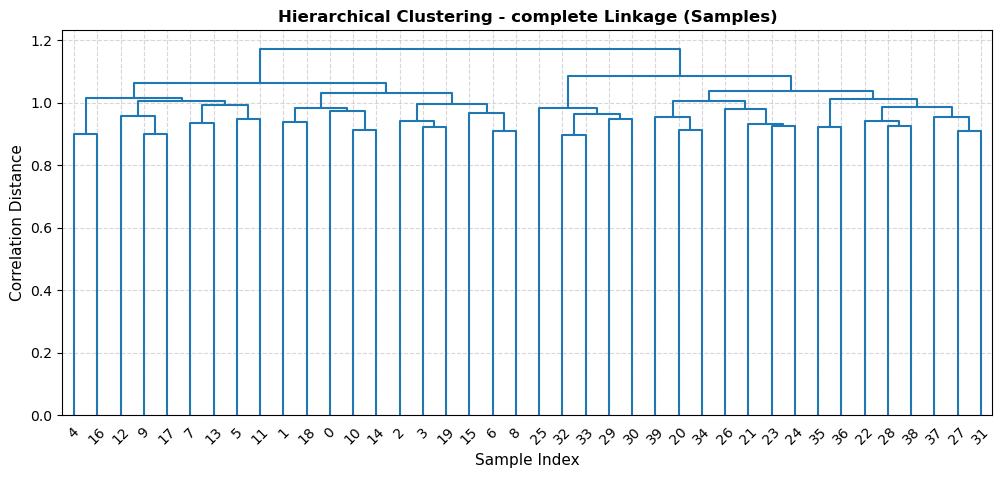

In [161]:
linkage_single = linkage(X_scaled, method='complete', metric='correlation')

plt.figure(figsize=(12, 5))
dendrogram(linkage_single, leaf_font_size=10)
plt.title('Hierarchical Clustering - complete Linkage (Samples)', fontsize=12, fontweight='bold')
plt.xlabel('Sample Index', fontsize=11)
plt.ylabel('Correlation Distance', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

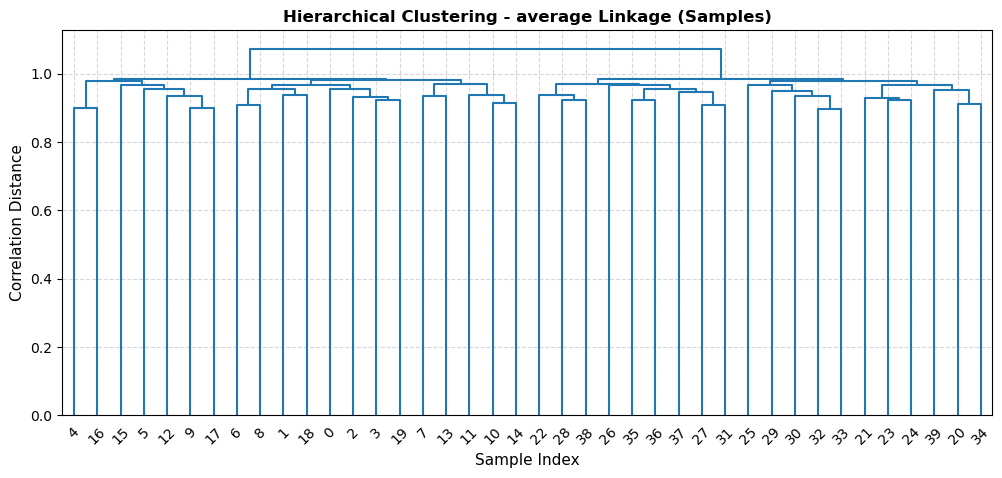

In [160]:
# Average linkage
linkage_single = linkage(X_scaled, method='average', metric='correlation')

plt.figure(figsize=(12, 5))
dendrogram(linkage_single, leaf_font_size=10)
plt.title('Hierarchical Clustering - average Linkage (Samples)', fontsize=12, fontweight='bold')
plt.xlabel('Sample Index', fontsize=11)
plt.ylabel('Correlation Distance', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

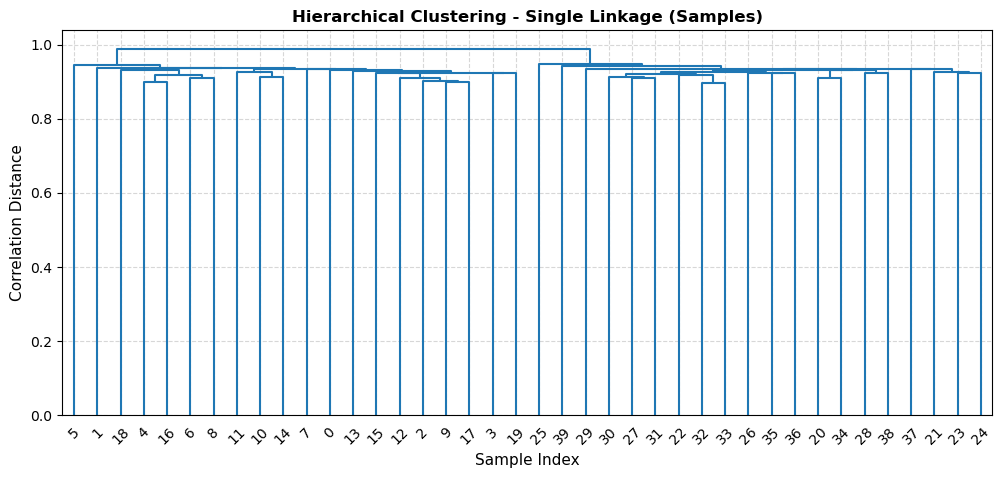

In [159]:


linkage_single = linkage(X_scaled, method='single', metric='correlation')

plt.figure(figsize=(12, 5))
dendrogram(linkage_single, leaf_font_size=10)
plt.title('Hierarchical Clustering - Single Linkage (Samples)', fontsize=12, fontweight='bold')
plt.xlabel('Sample Index', fontsize=11)
plt.ylabel('Correlation Distance', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

(c): Identifying Genes Differing Across Groups


To identify which genes differ the most across the two known groups (healthy vs. diseased), we can perform a **two-sample t-test** for each gene independently. Genes with the largest absolute t-statistics (and smallest p-values) exhibit the most significant mean expression differences between the two cohorts.

Alternatively, we could rank genes by the absolute difference between their group means or effect size (Cohen's $d$). Running a t-test naturally incorporates both the mean difference and the variance within each group.